In [3]:
pip install geopandas shapely pyogrio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

In [5]:
weather = pd.read_parquet(
    "../datasets/processed/weather_monthly.parquet"
)

weather.head()

,Date,Year,Month,Month_Name,Latitude,Longitude,Temperature_C,DewPoint_C,Rainfall_mm,Wind_Speed,Surface_Pressure_hPa
0,1997-01-01,1997,1,January,37.5,68.00,6.026093,-2.952881,0.484467,0.851831,947.438416
1,1997-01-01,1997,1,January,37.5,68.25,5.293671,-1.947021,0.486374,0.893243,950.488464
2,1997-01-01,1997,1,January,37.5,68.50,5.278046,-0.800537,0.476837,0.986747,961.558411
3,1997-01-01,1997,1,January,37.5,68.75,5.086639,-0.298584,0.549316,1.135211,965.148438
4,1997-01-01,1997,1,January,37.5,69.00,3.973358,-1.566162,0.820160,1.146364,944.078430


In [6]:
weather.shape

(3445764, 11)

In [7]:
weather.info

<bound method DataFrame.info of               Date  Year  Month Month_Name  Latitude  Longitude  \
0       1997-01-01  1997      1    January      37.5      68.00   
1       1997-01-01  1997      1    January      37.5      68.25   
2       1997-01-01  1997      1    January      37.5      68.50   
3       1997-01-01  1997      1    January      37.5      68.75   
4       1997-01-01  1997      1    January      37.5      69.00   
...            ...   ...    ...        ...       ...        ...   
3445759 2015-12-01  2015     12   December       6.0      96.50   
3445760 2015-12-01  2015     12   December       6.0      96.75   
3445761 2015-12-01  2015     12   December       6.0      97.00   
3445762 2015-12-01  2015     12   December       6.0      97.25   
3445763 2015-12-01  2015     12   December       6.0      97.50   

         Temperature_C  DewPoint_C  Rainfall_mm  Wind_Speed  \
0             6.026093   -2.952881     0.484467    0.851831   
1             5.293671   -1.947021   

In [8]:
weather.columns

Index(['Date', 'Year', 'Month', 'Month_Name', 'Latitude', 'Longitude',
       'Temperature_C', 'DewPoint_C', 'Rainfall_mm', 'Wind_Speed',
       'Surface_Pressure_hPa'],
      dtype='str')

In [9]:
states = gpd.read_file(
    "../datasets/raw/shapefiles/india_states/India_State_Boundary.shp"
)

In [10]:
states.head()

,State_Name,geometry
0,Andaman & Nicobar,"MULTIPOLYGON (((10341718.474 1449533.161, 1034..."
1,Chandigarh,"POLYGON ((8546255.616 3606050.813, 8546315.4 3..."
2,Daman and Diu and Dadra and Nagar Haveli,"MULTIPOLYGON (((8122247.822 2312434.407, 81223..."
3,Delhi,"POLYGON ((8583390.57 3359116.19, 8583476.212 3..."
4,Haryana,"POLYGON ((8524318.539 3516490.865, 8524451.392..."


In [11]:
states.columns

Index(['State_Name', 'geometry'], dtype='str')

In [12]:
states.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [13]:
states = states.to_crs(epsg=4326)

In [14]:
states.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [16]:
weather_gdf = gpd.GeoDataFrame(
    weather,
    geometry=gpd.points_from_xy(
        weather["Longitude"],
        weather["Latitude"]
    ),
    crs="EPSG:4326"
)

In [17]:
weather_gdf.head()

,Date,Year,Month,Month_Name,Latitude,Longitude,Temperature_C,DewPoint_C,Rainfall_mm,Wind_Speed,Surface_Pressure_hPa,geometry
0,1997-01-01,1997,1,January,37.5,68.00,6.026093,-2.952881,0.484467,0.851831,947.438416,POINT (68 37.5)
1,1997-01-01,1997,1,January,37.5,68.25,5.293671,-1.947021,0.486374,0.893243,950.488464,POINT (68.25 37.5)
2,1997-01-01,1997,1,January,37.5,68.50,5.278046,-0.800537,0.476837,0.986747,961.558411,POINT (68.5 37.5)
3,1997-01-01,1997,1,January,37.5,68.75,5.086639,-0.298584,0.549316,1.135211,965.148438,POINT (68.75 37.5)
4,1997-01-01,1997,1,January,37.5,69.00,3.973358,-1.566162,0.820160,1.146364,944.078430,POINT (69 37.5)


In [18]:
weather_state = gpd.sjoin(
    weather_gdf,
    states[["State_Name", "geometry"]],
    how="left",
    predicate="intersects"
)

In [19]:
print(weather_state.shape)

weather_state["State_Name"].isnull().sum()

(3445764, 14)


np.int64(2384652)

In [20]:
print(states.crs)
print(weather_gdf.crs)

EPSG:4326
EPSG:4326


In [21]:
states.total_bounds

array([68.12381591,  6.75407754, 97.40783632, 37.09701157])

In [22]:
states.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [23]:
weather_gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [24]:
print(weather["Latitude"].min(), weather["Latitude"].max())
print(weather["Longitude"].min(), weather["Longitude"].max())

6.0 37.5
68.0 97.5


In [25]:
weather[["Latitude", "Longitude"]].drop_duplicates().shape

(15113, 2)

In [18]:
weather_state["State_Name"].value_counts()

State_Name
Rajasthan                                   113316
Madhya Pradesh                              100092
Maharashtra                                  96444
Uttar Pradesh                                78204
Gujarat                                      60876
Ladakh                                       59736
Karnataka                                    57684
Andhra Pradesh                               51528
Odisha                                       49248
Chhattishgarh                                43092
Tamilnadu                                    39672
Telengana                                    34884
Bihar                                        30552
Arunachal Pradesh                            27588
West Bengal                                  26676
Assam                                        26448
Jharkhand                                    25992
Jammu and Kashmir                            20976
Himachal Pradesh                             18924
Uttarakhand         

In [19]:
print(states.total_bounds)

[68.12381591  6.75407754 97.40783632 37.09701157]


In [20]:
print(weather["Latitude"].min(), weather["Latitude"].max())
print(weather["Longitude"].min(), weather["Longitude"].max())

6.0 37.5
68.0 97.5


In [26]:
weather_points = weather[["Latitude", "Longitude"]].drop_duplicates()

weather_points = gpd.GeoDataFrame(
    weather_points,
    geometry=gpd.points_from_xy(
        weather_points["Longitude"],
        weather_points["Latitude"]
    ),
    crs="EPSG:4326"
)

In [27]:
weather_points_state = gpd.sjoin_nearest(
    weather_points,
    states[["State_Name", "geometry"]],
    how="left",
    distance_col="Distance"
)

c:\Users\anurag.prajapati\AppData\Local\Programs\Python\Python314\Lib\site-packages\geopandas\array.py:411: UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  warnings.warn(


In [28]:
weather_points_state["State_Name"].isnull().sum()

np.int64(0)

In [29]:
weather_points_state["Distance"].describe()

count    15113.000000
mean         1.816890
std          2.011299
min          0.000000
25%          0.000000
50%          1.144707
75%          3.150806
max          9.439838
Name: Distance, dtype: float64

In [30]:
weather = weather.merge(
    weather_points_state[
        ["Latitude", "Longitude", "State_Name"]
    ],
    on=["Latitude", "Longitude"],
    how="left"
)

In [31]:
weather["State_Name"].isnull().sum()

np.int64(0)

In [32]:
weather_points_state["Distance"].describe()

count    15113.000000
mean         1.816890
std          2.011299
min          0.000000
25%          0.000000
50%          1.144707
75%          3.150806
max          9.439838
Name: Distance, dtype: float64

In [33]:
weather.head()

,Date,Year,Month,Month_Name,Latitude,Longitude,Temperature_C,DewPoint_C,Rainfall_mm,Wind_Speed,Surface_Pressure_hPa,State_Name
0,1997-01-01,1997,1,January,37.5,68.00,6.026093,-2.952881,0.484467,0.851831,947.438416,Ladakh
1,1997-01-01,1997,1,January,37.5,68.25,5.293671,-1.947021,0.486374,0.893243,950.488464,Ladakh
2,1997-01-01,1997,1,January,37.5,68.50,5.278046,-0.800537,0.476837,0.986747,961.558411,Ladakh
3,1997-01-01,1997,1,January,37.5,68.75,5.086639,-0.298584,0.549316,1.135211,965.148438,Ladakh
4,1997-01-01,1997,1,January,37.5,69.00,3.973358,-1.566162,0.820160,1.146364,944.078430,Ladakh


In [34]:
state_weather = (
    weather
    .groupby(["State_Name", "Year", "Month"])
    .agg(
        Avg_Temperature_C=("Temperature_C", "mean"),
        Avg_DewPoint_C=("DewPoint_C", "mean"),
        Avg_Rainfall_mm=("Rainfall_mm", "mean"),
        Avg_Wind_Speed=("Wind_Speed", "mean"),
        Avg_Surface_Pressure_hPa=("Surface_Pressure_hPa", "mean"),
        Grid_Points=("Latitude", "count")
    )
    .reset_index()
)

In [35]:
state_weather.shape

(8208, 9)

In [36]:
state_weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 8208 entries, 0 to 8207
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   State_Name                8208 non-null   str    
 1   Year                      8208 non-null   int32  
 2   Month                     8208 non-null   int32  
 3   Avg_Temperature_C         8208 non-null   float32
 4   Avg_DewPoint_C            8208 non-null   float32
 5   Avg_Rainfall_mm           8208 non-null   float32
 6   Avg_Wind_Speed            8208 non-null   float32
 7   Avg_Surface_Pressure_hPa  8208 non-null   float32
 8   Grid_Points               8208 non-null   int64  
dtypes: float32(5), int32(2), int64(1), str(1)
memory usage: 436.2 KB


In [37]:
state_weather.isnull().sum()

State_Name                  0
Year                        0
Month                       0
Avg_Temperature_C           0
Avg_DewPoint_C              0
Avg_Rainfall_mm             0
Avg_Wind_Speed              0
Avg_Surface_Pressure_hPa    0
Grid_Points                 0
dtype: int64

In [38]:
state_weather.head()

,State_Name,Year,Month,Avg_Temperature_C,Avg_DewPoint_C,Avg_Rainfall_mm,Avg_Wind_Speed,Avg_Surface_Pressure_hPa,Grid_Points
0,Andaman & Nicobar,1997,1,25.635103,19.881298,0.396853,4.634264,1012.505066,2015
1,Andaman & Nicobar,1997,2,25.656574,20.198341,0.543375,4.130660,1011.125305,2015
2,Andaman & Nicobar,1997,3,27.208632,22.310066,0.312993,2.566630,1011.505737,2015
3,Andaman & Nicobar,1997,4,27.961119,22.881313,1.450820,1.879260,1010.482544,2015
4,Andaman & Nicobar,1997,5,28.352015,24.369240,7.076901,4.330473,1008.173584,2015


In [39]:
print("States:", state_weather["State_Name"].nunique())
print("Years:", state_weather["Year"].min(), "-", state_weather["Year"].max())
print("Months:", sorted(state_weather["Month"].unique()))

States: 36
Years: 1997 - 2015
Months: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]


In [40]:
state_weather.groupby("State_Name")["Grid_Points"].describe()

,count,mean,std,min,25%,50%,75%,max
State_Name,,,,,,,,
Andaman & Nicobar,228.0,2015.0,0.0,2015.0,2015.0,2015.0,2015.0,2015.0
Andhra Pradesh,228.0,706.0,0.0,706.0,706.0,706.0,706.0,706.0
Arunachal Pradesh,228.0,1273.0,0.0,1273.0,1273.0,1273.0,1273.0,1273.0
Assam,228.0,145.0,0.0,145.0,145.0,145.0,145.0,145.0
Bihar,228.0,325.0,0.0,325.0,325.0,325.0,325.0,325.0
Chandigarh,228.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Chhattishgarh,228.0,189.0,0.0,189.0,189.0,189.0,189.0,189.0
Daman and Diu and Dadra and Nagar Haveli,228.0,13.0,0.0,13.0,13.0,13.0,13.0,13.0
Delhi,228.0,3.0,0.0,3.0,3.0,3.0,3.0,3.0


In [41]:
state_weather.groupby("State_Name")["Grid_Points"].mean().sort_values()

State_Name
Chandigarh                                     1.0
Delhi                                          3.0
Puducherry                                     3.0
Daman and Diu and Dadra and Nagar Haveli      13.0
Goa                                           45.0
Nagaland                                      60.0
Haryana                                       65.0
Meghalaya                                     65.0
Tripura                                       86.0
Himachal Pradesh                              91.0
Jharkhand                                    114.0
Punjab                                       120.0
Assam                                        145.0
Telengana                                    153.0
Kerala                                       187.0
Chhattishgarh                                189.0
Manipur                                      204.0
Jammu and Kashmir                            284.0
Karnataka                                    307.0
Bihar               

In [42]:
weather.groupby("State_Name")[["Latitude", "Longitude"]].nunique()

,Latitude,Longitude
State_Name,,
Andaman & Nicobar,48,46
Andhra Pradesh,28,45
Arunachal Pradesh,54,31
Assam,17,25
Bihar,31,19
Chandigarh,1,1
Chhattishgarh,25,15
Daman and Diu and Dadra and Nagar Haveli,6,5
Delhi,2,2


In [43]:
weather[
    ["Latitude", "Longitude", "State_Name"]
].drop_duplicates()["State_Name"].value_counts()

State_Name
Andaman & Nicobar                           2015
Ladakh                                      1346
Arunachal Pradesh                           1273
Tamilnadu                                   1100
Rajasthan                                    915
Lakshadweep                                  895
Maharashtra                                  723
Andhra Pradesh                               706
Gujarat                                      587
Sikkim                                       578
Mizoram                                      494
Odisha                                       460
Madhya Pradesh                               439
Uttar Pradesh                                426
West Bengal                                  367
Uttarakhand                                  329
Bihar                                        325
Karnataka                                    307
Jammu and Kashmir                            284
Manipur                                      204
Chhattish

In [44]:
weather[["Latitude","Longitude"]].drop_duplicates().shape

(15113, 2)

In [45]:
weather_points_state["Distance"].sort_values(ascending=False).head(20)

87     9.439838
86     9.381021
88     9.378903
89     9.257933
206    9.191721
205    9.164041
207    9.162382
90     9.142201
85     9.137129
204    9.084746
208    9.038515
91     9.031908
326    8.947592
325    8.943709
92     8.927255
209    8.919937
324    8.915259
323    8.893748
84     8.893532
203    8.839750
Name: Distance, dtype: float64

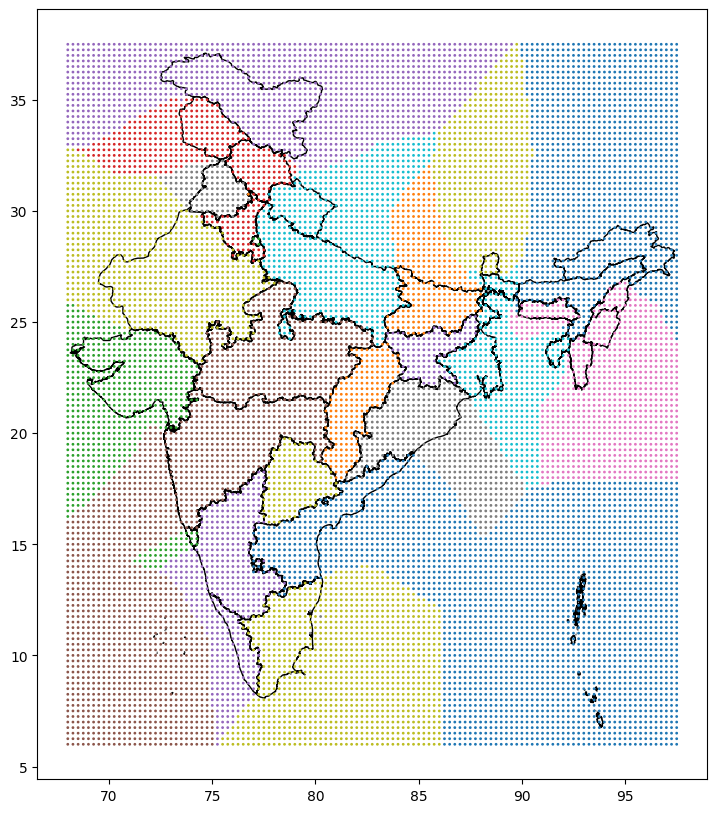

In [46]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,10))

states.plot(ax=ax, edgecolor="black", facecolor="none")

weather_points_state.plot(
    ax=ax,
    markersize=1,
    column="State_Name",
    legend=False
)

plt.show()

In [47]:
weather_points_state["Distance"].describe(percentiles=[0.90,0.95,0.99])

count    15113.000000
mean         1.816890
std          2.011299
min          0.000000
90%          4.733041
95%          5.778954
99%          7.778453
max          9.439838
Name: Distance, dtype: float64

In [48]:
weather[["Latitude","Longitude"]].drop_duplicates().shape

(15113, 2)

In [49]:
weather_points_state["Distance"].sort_values(ascending=False).head(20)

87     9.439838
86     9.381021
88     9.378903
89     9.257933
206    9.191721
205    9.164041
207    9.162382
90     9.142201
85     9.137129
204    9.084746
208    9.038515
91     9.031908
326    8.947592
325    8.943709
92     8.927255
209    8.919937
324    8.915259
323    8.893748
84     8.893532
203    8.839750
Name: Distance, dtype: float64

<Axes: >

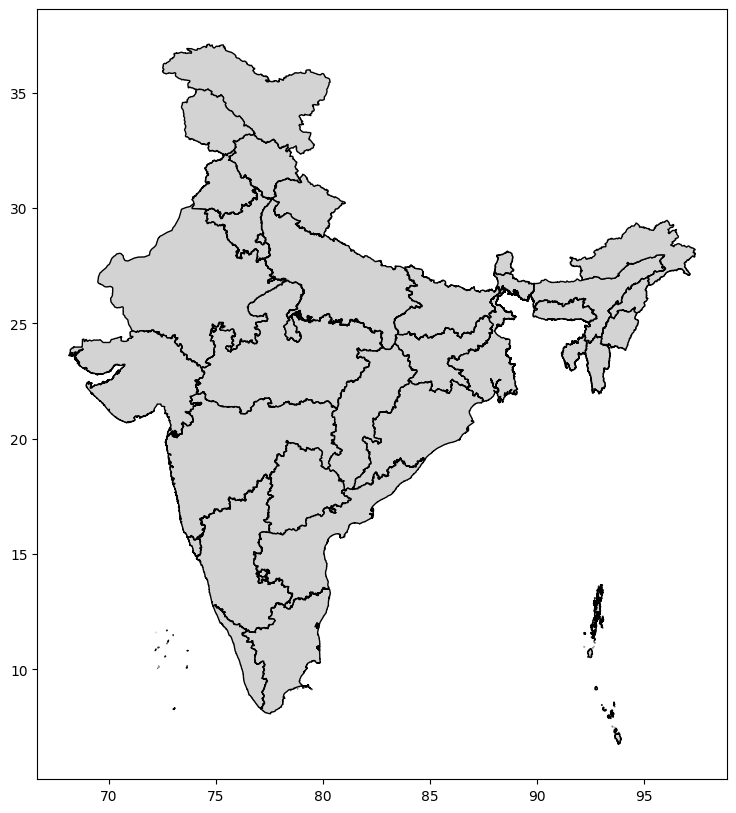

In [50]:
states.plot(figsize=(10, 10), edgecolor="black", facecolor="lightgray")

<Axes: >

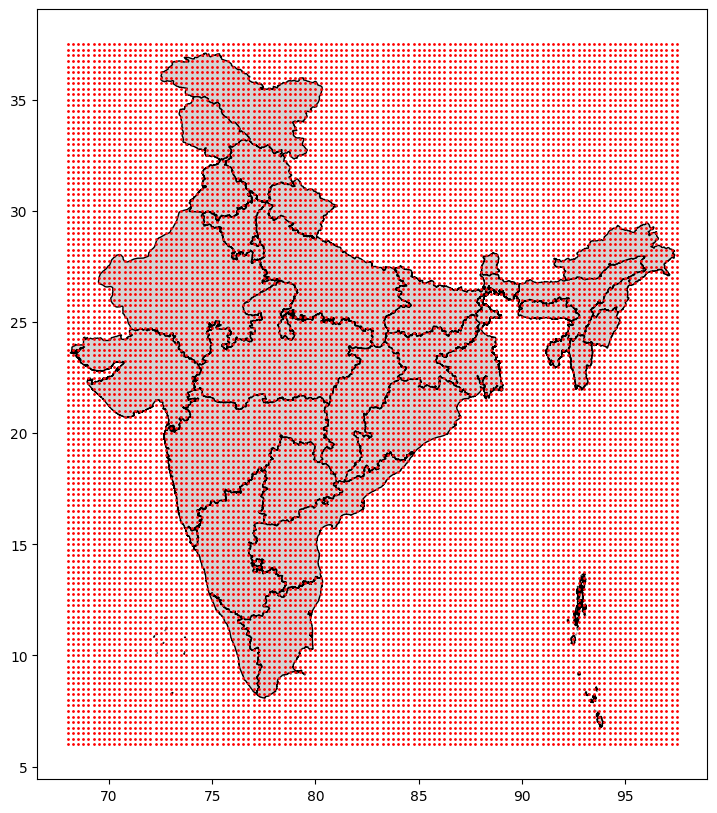

In [51]:
ax = states.plot(figsize=(10, 10), edgecolor="black", facecolor="lightgray")

weather_points.plot(
    ax=ax,
    markersize=1,
    color="red"
)

In [56]:
weather_points = weather_gdf[
    ["Latitude", "Longitude", "geometry"]
].drop_duplicates()

within_points = gpd.sjoin(
    weather_points,
    states[["State_Name", "geometry"]],
    how="inner",
    predicate="intersects"
)

print("Unique grid points:", len(weather_points))
print("Land points:", len(within_points))
print("Percentage:",
      len(within_points)/len(weather_points)*100)

Unique grid points: 15113
Land points: 4654
Percentage: 30.79468007675511


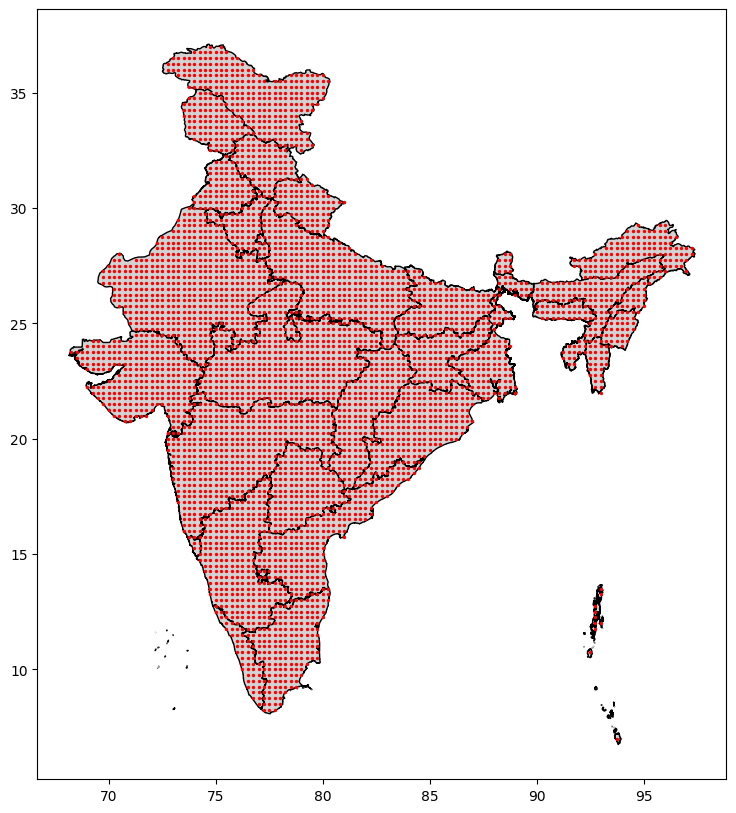

In [53]:
ax = states.plot(figsize=(10,10),
                 edgecolor="black",
                 facecolor="lightgray")

within_points.plot(
    ax=ax,
    color="red",
    markersize=2
)

plt.show()

In [54]:
within_points = gpd.sjoin(
    weather_points,
    states[["State_Name", "geometry"]],
    how="inner",
    predicate="intersects"
)

In [55]:
print(len(within_points))

4654


In [57]:
weather = weather.merge(
    within_points[
        ["Latitude", "Longitude", "State_Name"]
    ],
    on=["Latitude", "Longitude"],
    how="left"
)

In [62]:
weather = weather.dropna(subset=["State_Name"]).reset_index(drop=True)

In [61]:
weather.columns

Index(['Date', 'Year', 'Month', 'Month_Name', 'Latitude', 'Longitude',
       'Temperature_C', 'DewPoint_C', 'Rainfall_mm', 'Wind_Speed',
       'Surface_Pressure_hPa', 'State_Name'],
      dtype='str')

In [60]:
# Remove the old nearest-join column
weather = weather.drop(columns=["State_Name_x"])

# Rename the within-join column
weather = weather.rename(columns={
    "State_Name_y": "State_Name"
})

In [63]:
print(weather.shape)
print(weather["State_Name"].isnull().sum())

(1061112, 12)
0


In [64]:
state_weather = (
    weather
    .groupby(["State_Name", "Year", "Month"])
    .agg(
        Avg_Temperature_C=("Temperature_C", "mean"),
        Avg_DewPoint_C=("DewPoint_C", "mean"),
        Avg_Rainfall_mm=("Rainfall_mm", "mean"),
        Avg_Wind_Speed=("Wind_Speed", "mean"),
        Avg_Surface_Pressure_hPa=("Surface_Pressure_hPa", "mean"),
        Grid_Points=("Latitude", "count")
    )
    .reset_index()
)

In [65]:
state_mapping = {
    "Tamilnadu": "Tamil Nadu",
    "Telengana": "Telangana",
    "Chhattishgarh": "Chhattisgarh",
    "Andaman & Nicobar": "Andaman and Nicobar Islands",
}

In [68]:
import glob
import pandas as pd

files = glob.glob("../datasets/cleaned/crop_price/*.parquet")

price_states = set()

for file in files:
    df = pd.read_parquet(file, columns=["State"])
    price_states.update(df["State"].unique())

price_states = set(price_states)

In [71]:
production = pd.read_csv("../datasets/cleaned/crop_production_clean.csv")

production_states = set(production["State_Name"].unique())

In [72]:
weather_states = set(state_weather["State_Name"].unique())

In [73]:
print("Weather not in Production")
print(sorted(weather_states - production_states))

print("\nProduction not in Weather")
print(sorted(production_states - weather_states))

print("\nPrice not in Weather")
print(sorted(price_states - weather_states))

print("\nWeather not in Price")
print(sorted(weather_states - price_states))

Weather not in Production
['Andaman & Nicobar', 'Chhattishgarh', 'Daman and Diu and Dadra and Nagar Haveli', 'Delhi', 'Jammu and Kashmir', 'Ladakh', 'Tamilnadu', 'Telengana']

Production not in Weather
['Andaman And Nicobar Islands', 'Chhattisgarh', 'Dadra And Nagar Haveli', 'Jammu And Kashmir', 'Tamil Nadu', 'Telangana']

Price not in Weather
['Andaman and Nicobar', 'Chattisgarh', 'NCT of Delhi', 'Pondicherry', 'Tamil Nadu', 'Telangana', 'Uttrakhand']

Weather not in Price
['Andaman & Nicobar', 'Chhattishgarh', 'Daman and Diu and Dadra and Nagar Haveli', 'Delhi', 'Ladakh', 'Puducherry', 'Tamilnadu', 'Telengana']


In [77]:
weather_state_mapping = {
    "Andaman & Nicobar": "Andaman And Nicobar Islands",
    "Chhattishgarh": "Chhattisgarh",
    "Tamilnadu": "Tamil Nadu",
    "Telengana": "Telangana",
    "Jammu and Kashmir": "Jammu And Kashmir",
}

In [78]:
state_weather["State_Name"] = (
    state_weather["State_Name"]
    .replace(weather_state_mapping)
)

In [76]:
price_state_mapping = {
    "Andaman and Nicobar": "Andaman And Nicobar Islands",
    "Chattisgarh": "Chhattisgarh",
    "NCT of Delhi": "Delhi",
    "Pondicherry": "Puducherry",
    "Tamil Nadu": "Tamil Nadu",
    "Telangana": "Telangana",
    "Uttrakhand": "Uttarakhand",
}

In [79]:
state_weather.to_parquet(
    "../datasets/processed/state_monthly_weather.parquet",
    index=False
)

state_weather.to_csv(
    "../datasets/processed/state_monthly_weather.csv",
    index=False
)